In [6]:
from pathlib import Path
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)

# Visual styling
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

In [7]:
# 1. Load labeled transactions from Parquet
data_path = Path("../data/elliptic_txs_labeled.parquet")
if not data_path.exists():
    raise FileNotFoundError(f"Missing {data_path.resolve()}. Please run Notebook 1 Cell 4 first.")

df = pd.read_parquet(data_path)

# 2. Out-of-Time (OOT) Split: Train (Steps 1-34), Test (Steps 35-49)
train_df = df[df["time_step"] <= 34].copy()
test_df = df[df["time_step"] >= 35].copy()

# Feature matrix specification: degree metrics + local features + neighborhood aggregates
exclude_cols = ["txId", "time_step", "class", "class_label"]
feature_cols = [c for c in df.columns if c not in exclude_cols]

X_train, y_train = train_df[feature_cols], train_df["class_label"]
X_test, y_test = test_df[feature_cols], test_df["class_label"]

print("=" * 70)
print(f"Total Features Utilized: {len(feature_cols)}")
print(f"Train Cohort (Steps  1-34): {len(train_df):,} samples | Illicit: {y_train.sum():,} ({y_train.mean()*100:.2f}%)")
print(f"Test Cohort  (Steps 35-49): {len(test_df):,} samples | Illicit: {y_test.sum():,} ({y_test.mean()*100:.2f}%)")
print("=" * 70)

Total Features Utilized: 168
Train Cohort (Steps  1-34): 29,894 samples | Illicit: 3,462 (11.58%)
Test Cohort  (Steps 35-49): 16,670 samples | Illicit: 1,083 (6.50%)


In [8]:
# Helper function to evaluate illicit detection efficacy
def evaluate_aml_model(name, y_true, y_pred, y_prob):
    p = precision_score(y_true, y_pred, pos_label=1, zero_division=0)
    r = recall_score(y_true, y_pred, pos_label=1, zero_division=0)
    f1 = f1_score(y_true, y_pred, pos_label=1, zero_division=0)
    pr_auc = average_precision_score(y_true, y_prob)
    roc_auc = roc_auc_score(y_true, y_prob)
    
    return {
        "Model": name,
        "Illicit Precision": round(p, 4),
        "Illicit Recall": round(r, 4),
        "Illicit F1": round(f1, 4),
        "PR-AUC": round(pr_auc, 4),
        "ROC-AUC": round(roc_auc, 4),
    }

results = []

In [9]:
# 3. Model 1: Random Forest Baseline (Balanced Class Weights)
print("\nTraining Random Forest baseline...")
rf = RandomForestClassifier(
    n_estimators=150,
    max_depth=15,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)

rf_prob = rf.predict_proba(X_test)[:, 1]
rf_pred = (rf_prob >= 0.50).astype(int)
results.append(evaluate_aml_model("Random Forest (Balanced)", y_test, rf_pred, rf_prob))

# 4. Model 2: LightGBM Baseline (Scale Pos Weight)
print("Training LightGBM baseline...")
scale_pos_weight = (len(y_train) - y_train.sum()) / y_train.sum()

lgb_model = lgb.LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
lgb_model.fit(X_train, y_train)

# Call predict_proba on lgb_model, NOT lgb
lgb_prob = lgb_model.predict_proba(X_test)[:, 1]
lgb_pred = (lgb_prob >= 0.50).astype(int)
results.append(evaluate_aml_model("LightGBM (Scale Pos Weight)", y_test, lgb_pred, lgb_prob))

# 5. Summary Evaluation Matrix
results_df = pd.DataFrame(results)
display(results_df)


Training Random Forest baseline...
Training LightGBM baseline...


,Model,Illicit Precision,Illicit Recall,Illicit F1,PR-AUC,ROC-AUC
0,Random Forest (Balanced),0.7834,0.7313,0.7564,0.7941,0.9390
1,LightGBM (Scale Pos Weight),0.7580,0.7461,0.7520,0.8049,0.9387


Precision-Recall Curves & Operational AML Threshold Tuning

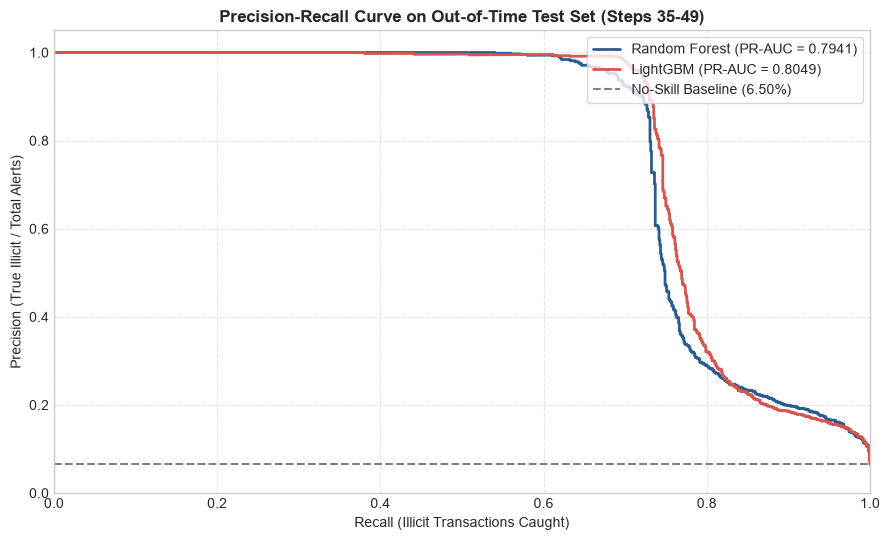

OPERATIONAL AML DECISION THRESHOLD BENCHMARK (LightGBM)


,Threshold Strategy,Cutoff (tau),Total Alerts (TP+FP),Illicit Caught (TP),False Alerts (FP),Missed Illicit (FN),Precision,Recall,F1-Score
0,Default (0.50),0.5000,"1,066",808,258,275,75.80%,74.61%,0.7520
1,Max F1 (0.832),0.8325,815,780,35,303,95.71%,72.02%,0.8219
2,High-Stringency / 80% Recall (0.080),0.0805,"2,705",867,"1,838",216,32.05%,80.06%,0.4578


In [10]:
# 1. Compute Precision-Recall curves
prec_rf, rec_rf, thresh_rf = precision_recall_curve(y_test, rf_prob)
prec_lgb, rec_lgb, thresh_lgb = precision_recall_curve(y_test, lgb_prob)

# Compute PR-AUC (Average Precision)
ap_rf = average_precision_score(y_test, rf_prob)
ap_lgb = average_precision_score(y_test, lgb_prob)
baseline_rate = y_test.mean()

# 2. Visualize Precision-Recall curves
fig, ax = plt.subplots(figsize=(9, 5.5))

ax.plot(rec_rf, prec_rf, label=f"Random Forest (PR-AUC = {ap_rf:.4f})", color="#2b5c8f", lw=2)
ax.plot(rec_lgb, prec_lgb, label=f"LightGBM (PR-AUC = {ap_lgb:.4f})", color="#d9534f", lw=2)
ax.axhline(y=baseline_rate, color="gray", linestyle="--", label=f"No-Skill Baseline ({baseline_rate*100:.2f}%)")

ax.set_title("Precision-Recall Curve on Out-of-Time Test Set (Steps 35-49)", fontsize=12, fontweight="bold")
ax.set_xlabel("Recall (Illicit Transactions Caught)", fontsize=10)
ax.set_ylabel("Precision (True Illicit / Total Alerts)", fontsize=10)
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.legend(loc="upper right", frameon=True)
ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# 3. Find Optimal Thresholds for LightGBM
# Calculate F1 score across all thresholds (excluding last point of PR curve)
f1_scores = 2 * (prec_lgb[:-1] * rec_lgb[:-1]) / (prec_lgb[:-1] + rec_lgb[:-1] + 1e-10)
best_idx = np.argmax(f1_scores)
best_thresh = thresh_lgb[best_idx]
best_f1 = f1_scores[best_idx]

# Target 80% Recall threshold for high-stringency compliance
target_recall = 0.80
idx_80 = np.where(rec_lgb[:-1] >= target_recall)[0][-1]
thresh_80 = thresh_lgb[idx_80]

# 4. Comparative Threshold Strategy Evaluation
threshold_scenarios = [
    ("Default (0.50)", 0.50),
    (f"Max F1 ({best_thresh:.3f})", best_thresh),
    (f"High-Stringency / 80% Recall ({thresh_80:.3f})", thresh_80)
]

threshold_results = []
for name, t in threshold_scenarios:
    preds = (lgb_prob >= t).astype(int)
    cm = confusion_matrix(y_test, preds)
    tn, fp, fn, tp = cm.ravel()
    
    threshold_results.append({
        "Threshold Strategy": name,
        "Cutoff (tau)": round(t, 4),
        "Total Alerts (TP+FP)": f"{tp + fp:,}",
        "Illicit Caught (TP)": f"{tp:,}",
        "False Alerts (FP)": f"{fp:,}",
        "Missed Illicit (FN)": f"{fn:,}",
        "Precision": f"{precision_score(y_test, preds, pos_label=1, zero_division=0)*100:.2f}%",
        "Recall": f"{recall_score(y_test, preds, pos_label=1, zero_division=0)*100:.2f}%",
        "F1-Score": f"{f1_score(y_test, preds, pos_label=1, zero_division=0):.4f}"
    })

print("=" * 80)
print("OPERATIONAL AML DECISION THRESHOLD BENCHMARK (LightGBM)")
print("=" * 80)
display(pd.DataFrame(threshold_results))

Feature Importance & Local vs. Graph Aggregate Attribution

FEATURE FAMILY ATTRIBUTION SHARE (LIGHTGBM GAIN)
Local Transaction Attributes    :  80.56% of total model gain
1-Hop Neighborhood Aggregates   :  19.35% of total model gain
Graph Topology (Degree)         :   0.09% of total model gain


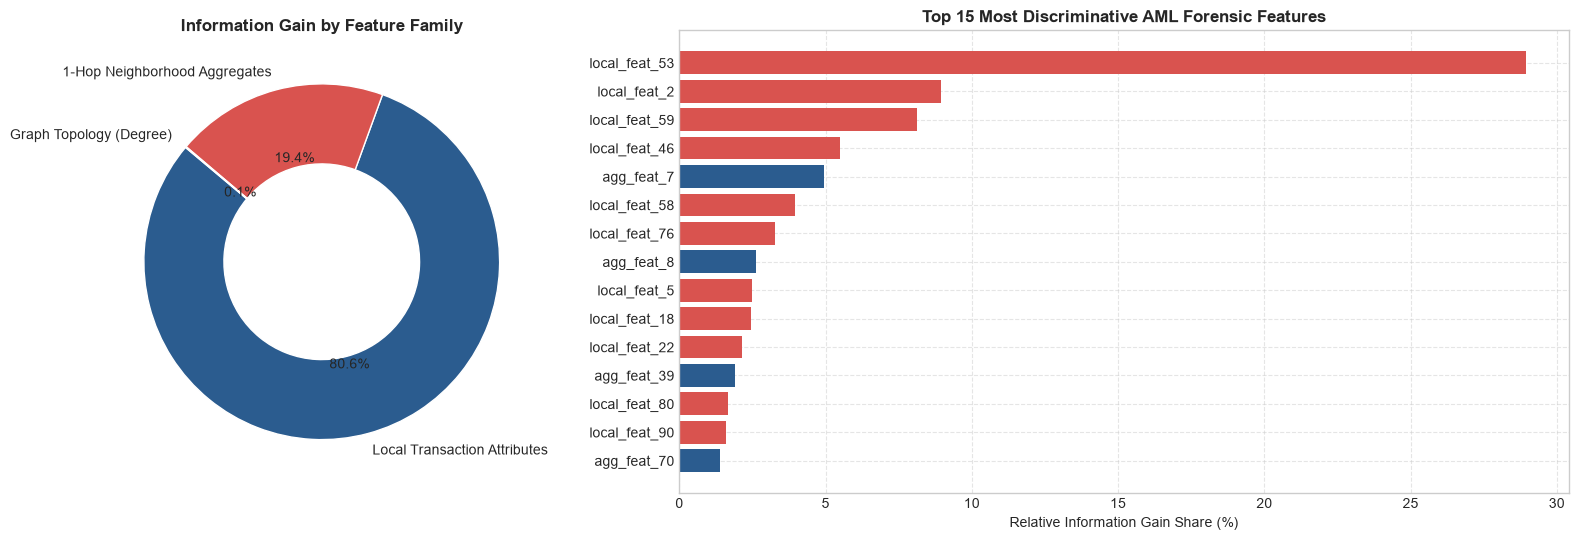

,feature,feature_family,gain_share_pct,importance_split
0,local_feat_53,Local Transaction Attributes,28.96%,335
1,local_feat_2,Local Transaction Attributes,8.93%,376
2,local_feat_59,Local Transaction Attributes,8.13%,110
3,local_feat_46,Local Transaction Attributes,5.50%,108
4,agg_feat_7,1-Hop Neighborhood Aggregates,4.95%,88
5,local_feat_58,Local Transaction Attributes,3.97%,118
6,local_feat_76,Local Transaction Attributes,3.25%,54
7,agg_feat_8,1-Hop Neighborhood Aggregates,2.61%,37
8,local_feat_5,Local Transaction Attributes,2.50%,67
9,local_feat_18,Local Transaction Attributes,2.43%,50


In [11]:
# 1. Extract feature importances from LightGBM
importance_df = pd.DataFrame({
    "feature": feature_cols,
    "importance_gain": lgb_model.booster_.feature_importance(importance_type="gain"),
    "importance_split": lgb_model.booster_.feature_importance(importance_type="split")
})

# Normalize gain to relative percentage share
importance_df["gain_share_pct"] = (
    importance_df["importance_gain"] / importance_df["importance_gain"].sum() * 100
)

# 2. Classify features into structural categories
def classify_feature_family(name):
    if "degree" in name:
        return "Graph Topology (Degree)"
    elif "agg_feat" in name:
        return "1-Hop Neighborhood Aggregates"
    elif "local_feat" in name:
        return "Local Transaction Attributes"
    return "Other"

importance_df["feature_family"] = importance_df["feature"].apply(classify_feature_family)

# 3. Aggregate importance share by feature family
family_summary = (
    importance_df.groupby("feature_family")["gain_share_pct"]
    .sum()
    .reset_index()
    .sort_values("gain_share_pct", ascending=False)
)

print("=" * 70)
print("FEATURE FAMILY ATTRIBUTION SHARE (LIGHTGBM GAIN)")
print("=" * 70)
for _, row in family_summary.iterrows():
    print(f"{row['feature_family']:<32}: {row['gain_share_pct']:>6.2f}% of total model gain")
print("=" * 70)

# 4. Visualizations: Family Breakdown & Top 15 Individual Features
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1, 2]})

# Left: Donut Chart of Feature Family Shares
colors = ["#2b5c8f", "#d9534f", "#e67e22"]
ax1.pie(
    family_summary["gain_share_pct"],
    labels=family_summary["feature_family"],
    autopct="%1.1f%%",
    startangle=140,
    colors=colors,
    wedgeprops=dict(width=0.45, edgecolor="white")
)
ax1.set_title("Information Gain by Feature Family", fontsize=12, fontweight="bold")

# Right: Top 15 Forensic Drivers by Information Gain
top15 = importance_df.sort_values("gain_share_pct", ascending=True).tail(15)

# Map bar colors to match category palette
bar_colors = top15["feature_family"].map({
    "1-Hop Neighborhood Aggregates": "#2b5c8f",
    "Local Transaction Attributes": "#d9534f",
    "Graph Topology (Degree)": "#e67e22"
})

ax2.barh(top15["feature"], top15["gain_share_pct"], color=bar_colors)
ax2.set_xlabel("Relative Information Gain Share (%)", fontsize=10)
ax2.set_title("Top 15 Most Discriminative AML Forensic Features", fontsize=12, fontweight="bold")
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# 5. Tabular inspection of top features
display(
    importance_df.sort_values("gain_share_pct", ascending=False)
    .head(10)[["feature", "feature_family", "gain_share_pct", "importance_split"]]
    .reset_index(drop=True)
    .style.format({"gain_share_pct": "{:.2f}%"})
)

Export Model Artifacts, Benchmarks & Predictions

In [12]:
import json
import joblib
from pathlib import Path

# 1. Establish export directories
models_dir = Path("../models")
reports_dir = Path("../reports")
data_dir = Path("../data")

for d in [models_dir, reports_dir]:
    d.mkdir(parents=True, exist_ok=True)

# 2. Persist trained estimators
joblib.dump(rf, models_dir / "random_forest_baseline.joblib")
joblib.dump(lgb_model, models_dir / "lightgbm_baseline.joblib")
print(f"Persisted models to: {models_dir.resolve()}")

# 3. Export threshold calibration & performance metadata
calibration_metadata = {
    "project": "crypto-forensics-illicit-detection",
    "train_time_steps": "1-34",
    "test_time_steps": "35-49",
    "n_train_samples": int(len(train_df)),
    "n_test_samples": int(len(test_df)),
    "n_features": len(feature_cols),
    "optimal_threshold_f1": float(best_thresh),
    "optimal_f1_score": float(best_f1),
    "threshold_recall_80": float(thresh_80),
    "model_benchmarks": results_df.to_dict(orient="records"),
    "feature_family_shares": family_summary.to_dict(orient="records")
}

with open(reports_dir / "model_evaluation_metrics.json", "w") as f:
    json.dump(calibration_metadata, f, indent=4)
print(f"Exported evaluation metrics to: {reports_dir / 'model_evaluation_metrics.json'}")

# 4. Save test-set predictions for temporal stability analysis in Notebook 3
test_predictions_df = test_df[["txId", "time_step", "class_label"]].copy()
test_predictions_df["rf_prob"] = rf_prob
test_predictions_df["lgb_prob"] = lgb_prob
test_predictions_df["lgb_pred_default"] = (lgb_prob >= 0.50).astype(int)
test_predictions_df["lgb_pred_optimal"] = (lgb_prob >= best_thresh).astype(int)

test_predictions_df.to_parquet(
    data_dir / "test_predictions_temporal.parquet",
    index=False,
    compression="snappy"
)
print(f"Exported test inference matrix to: {data_dir / 'test_predictions_temporal.parquet'}")

print("\n" + "=" * 70)
print("NOTEBOOK 2 COMPLETE: BASELINE BENCHMARKS & ARTIFACTS PERSISTED")
print("=" * 70)

Persisted models to: C:\Users\lxx55\crypto-forensics-illicit-detection\models
Exported evaluation metrics to: ..\reports\model_evaluation_metrics.json
Exported test inference matrix to: ..\data\test_predictions_temporal.parquet

NOTEBOOK 2 COMPLETE: BASELINE BENCHMARKS & ARTIFACTS PERSISTED
